In [1]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import joblib

import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import StandardScaler

from scipy import stats


# Data Preprocessing
### Includes any change made to the data before applying feature selection: imputation, normalisation. etc.

In [2]:
# viewing data and datatypes (numerical / categorical)
dataset = pd.read_csv("./datasets/TrainDataset2025.csv")
dataset.head(10)

,ID,pCR (outcome),RelapseFreeSurvival (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,TRG002174,1,144.0,41.0,0,0,0,1,3,3,...,0.517172,0.375126,3.325332,0.002314,3.880772e+06,473.464852,0.000768,0.182615,0.030508,0.000758
1,TRG002178,0,142.0,39.0,1,1,0,0,3,3,...,0.444391,0.444391,3.032144,0.005612,2.372010e+06,59.459710,0.004383,0.032012,0.001006,0.003685
2,TRG002204,1,135.0,31.0,0,0,0,1,2,1,...,0.534549,0.534549,2.485848,0.006752,1.540027e+06,33.935384,0.007584,0.024062,0.000529,0.006447
3,TRG002206,0,12.0,35.0,0,0,0,1,3,3,...,0.506185,0.506185,2.606255,0.003755,6.936741e+06,46.859265,0.005424,0.013707,0.000178,0.004543
4,TRG002210,0,109.0,61.0,1,0,0,0,2,1,...,0.462282,0.462282,2.809279,0.006521,1.265399e+06,39.621023,0.006585,0.034148,0.001083,0.005626
5,TRG002225,0,135.0,49.0,0,0,0,1,3,3,...,0.532369,0.532369,2.661106,0.007079,1.795207e+06,101.316642,0.002652,0.053378,0.002770,0.002263
6,TRG002228,0,139.0,56.0,0,0,0,1,3,2,...,0.513590,0.513590,2.745216,0.003993,1.142859e+07,131.839592,0.001949,0.021567,0.000446,0.001669
7,TRG002234,0,17.0,41.0,0,0,0,1,3,2,...,0.476326,0.476326,3.099632,0.008650,1.032117e+06,96.947959,0.002821,0.069697,0.004285,0.002475
8,TRG002237,0,139.0,46.0,0,0,0,1,2,1,...,0.534279,0.534279,2.515057,0.004309,2.122739e+06,26.938952,0.009552,0.021483,0.000463,0.008248
9,TRG002241,0,138.0,50.0,0,0,1,0,2,1,...,0.517795,0.517795,2.547969,0.003804,2.725950e+06,29.577853,0.008596,0.013617,0.000175,0.007353


In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Columns: 121 entries, ID to original_ngtdm_Strength
dtypes: float64(108), int64(12), object(1)
memory usage: 378.2+ KB


In [4]:
# Calculate some statistical points about the dataset columns (features and RFS target variable)
dataset.describe()

,pCR (outcome),RelapseFreeSurvival (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.00000,...,4.000000e+02,4.000000e+02,4.000000e+02,400.000000,4.000000e+02,400.000000,400.000000,400.000000,400.000000,400.000000
mean,12.697500,56.000208,51.804674,0.547500,2.902500,2.797500,2.830000,9.875000,6.562500,8.63250,...,3.957637e-01,3.911005e-01,2.722189e+00,0.003347,5.679717e+07,178.311246,32500.032620,0.056935,0.005965,0.029322
std,111.107417,27.137584,10.948522,0.498362,49.932114,49.937068,49.935558,86.092911,70.444284,86.20034,...,1.666319e-01,1.615922e-01,7.648849e-01,0.002419,7.063846e+08,1045.453432,177545.921568,0.047179,0.008379,0.115915
min,0.000000,0.000000,23.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.00000,...,7.050000e-11,7.050000e-11,-3.200000e-16,0.000008,0.000000e+00,0.000000,0.000248,0.000000,0.000000,0.000000
25%,0.000000,38.000000,44.516769,0.000000,0.000000,0.000000,0.000000,2.000000,1.000000,1.00000,...,3.199017e-01,3.184398e-01,2.340783e+00,0.001389,1.030473e+06,18.760570,0.001826,0.018628,0.000310,0.001464
50%,0.000000,55.000000,51.019507,1.000000,0.000000,0.000000,0.000000,2.000000,1.000000,1.00000,...,4.095627e-01,4.054695e-01,2.814884e+00,0.002944,3.277334e+06,67.929659,0.004383,0.047740,0.002330,0.003276
75%,0.000000,73.000000,60.000000,1.000000,1.000000,1.000000,1.000000,3.000000,2.000000,1.00000,...,5.000049e-01,4.956920e-01,3.304411e+00,0.004798,9.079686e+06,157.370294,0.013769,0.085321,0.007962,0.009479
max,999.000000,144.000000,79.603012,1.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.00000,...,8.773779e-01,8.571429e-01,4.947427e+00,0.011301,1.390001e+10,20764.693790,1000000.000000,0.285100,0.060742,1.145601


In [5]:
# Split data into features and target variable for the regression task

## Target variable
y = dataset['RelapseFreeSurvival (outcome)']

## Features
x = dataset.drop(['ID', 'pCR (outcome)', 'RelapseFreeSurvival (outcome)'], axis = 1)


In [6]:
print(x.select_dtypes(np.int64))

print("Before: "+str(x.select_dtypes(np.int64).shape))

#x['Age'] = x['Age'].astype(np.int64)

x['original_shape_VoxelVolume'] = x['original_shape_VoxelVolume'].astype(np.float64)


print("After: "+str(x.select_dtypes(np.int64).shape))

# Save column names of categorical features (clinical)
categorical_names = x.select_dtypes(np.int64).columns
categorical_names



     ER  PgR  HER2  TrippleNegative  ChemoGrade  Proliferation  HistologyType  \
0     0    0     0                1           3              3              1   
1     1    1     0                0           3              3              1   
2     0    0     0                1           2              1              1   
3     0    0     0                1           3              3              1   
4     1    0     0                0           2              1              1   
..   ..  ...   ...              ...         ...            ...            ...   
395   1    0     1                0           3              2              1   
396   0    0     0                1           3              3              1   
397   0    0     0                1           2              1              1   
398   1    0     0                0           3              3              1   
399   1    0     0                0           2              1              1   

     LNStatus  TumourStage 

Index(['ER', 'PgR', 'HER2', 'TrippleNegative', 'ChemoGrade', 'Proliferation',
       'HistologyType', 'LNStatus', 'TumourStage', 'Gene'],
      dtype='object')

## Type-specific preprocessing
### Dataset datatypes include: object, float64 and int64
    # object: ID Column
    # float64: Continuous features
    # int64: Categorical features

### Handling object datatype
1. Remove object datatype

This only contains the ID column

In [7]:
# Handling object datatype
#print(dataset_x_all.select_dtypes(object)) # ID Column

#print("Before: "+str(dataset_x_all.select_dtypes(object).shape))

#dataset_x_all = dataset_x_all.drop("ID",axis=1)
#print("After: "+str(dataset_x_all.select_dtypes(object).shape))


### Handling int64 datatype
#### Categorical Features
1. Remove non-categorical features

'original_shape_VoxelVolume' feature is int, but seems it should be float like the rest of the medical imaging features


### Handling float64 datatype
#### Continuous Features

Age is considered a continuous feature as there are continuous values in the dataset
- Considered converting to int, but this would truncate potentially valuable data and lead to Curse of Dimensionality if using an encoding technique later on.

In [8]:
# Save column names of continuous features (medical imaging, and age)
x['original_shape_VoxelVolume'] = x['original_shape_VoxelVolume'].astype(np.float64)
continuous_names = x.select_dtypes(np.float64).columns
continuous_names

Index(['Age', 'original_shape_Elongation', 'original_shape_Flatness',
       'original_shape_LeastAxisLength', 'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_Maximum2DDiameterSlice',
       'original_shape_Maximum3DDiameter', 'original_shape_MeshVolume',
       ...
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_glszm_SmallAreaLowGrayLevelEmphasis',
       'original_glszm_ZoneEntropy', 'original_glszm_ZonePercentage',
       'original_glszm_ZoneVariance', 'original_ngtdm_Busyness',
       'original_ngtdm_Coarseness', 'original_ngtdm_Complexity',
       'original_ngtdm_Contrast', 'original_ngtdm_Strength'],
      dtype='object', length=108)

In [9]:
x[categorical_names]

,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,Gene
0,0,0,0,1,3,3,1,1,2,1
1,1,1,0,0,3,3,1,1,2,0
2,0,0,0,1,2,1,1,0,2,1
3,0,0,0,1,3,3,1,1,3,1
4,1,0,0,0,2,1,1,0,2,1
...,...,...,...,...,...,...,...,...,...,...
395,1,0,1,0,3,2,1,1,4,0
396,0,0,0,1,3,3,1,0,2,0
397,0,0,0,1,2,1,1,0,2,0
398,1,0,0,0,3,3,1,1,3,0


### Handling 999 values
Issue: Can't replace all '999' with np.nan. This converts int64 to float64 as NaN is float64
- Solution: by saving column names, in datatype-specific handling, for int64 (categorical) features, no longer a need to preserve int64 as no data is lost when converting to float

In [10]:
# Replace 999 (placeholder) with NaN
x = x.replace([999],np.nan)

# Viewing features with null values
missing_values = x.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values

PgR                 1
HER2                1
TrippleNegative     1
ChemoGrade          3
Proliferation       2
HistologyType       3
LNStatus            1
Gene               88
dtype: int64

## General Preprocessing
1. Train-Test Split
2. Check for Duplicate Rows
2. Outlier Handling
3. Data Imputation
4. a - Data Normalisation | b - One-Hot Encoding

### 1. Train-Test Split

In [11]:
# Split the dataset into 80% for training data and 20% for testing data, with a specified random state
r_state = 12
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = r_state)
X_train

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
199,36.783025,0,1.0,0.0,0.0,3.0,3.0,1.0,0.0,3,...,0.350799,0.350799,3.197160,0.003696,9.762004e+05,74.501409,0.004012,0.102368,0.011175,0.003570
43,69.000000,0,0.0,1.0,0.0,2.0,1.0,1.0,1.0,2,...,0.550507,0.550507,2.573220,0.005959,1.052641e+06,21.346044,0.012082,0.024663,0.000567,0.010516
307,60.000000,0,0.0,0.0,1.0,2.0,1.0,1.0,1.0,1,...,0.426840,0.426840,2.956748,0.007522,4.830177e+05,38.839662,0.007064,0.066551,0.004116,0.006365
166,38.143737,1,1.0,1.0,0.0,3.0,2.0,1.0,0.0,2,...,0.572002,0.572002,2.000000,0.002920,1.720824e+06,8.240840,0.030818,0.011843,0.000150,0.025057
64,45.653662,0,0.0,1.0,0.0,3.0,2.0,1.0,0.0,3,...,0.584634,0.583599,2.398050,0.002764,1.202316e+07,163.782516,0.001637,0.033111,0.001479,0.001571
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241,71.300000,0,0.0,0.0,1.0,3.0,3.0,1.0,1.0,2,...,0.411956,0.411956,3.573921,0.004671,8.211440e+06,448.101792,0.000618,0.073363,0.005057,0.000545
253,63.238877,0,0.0,1.0,0.0,2.0,3.0,1.0,1.0,3,...,0.409377,0.409376,3.305045,0.001730,6.755623e+06,476.373341,0.000653,0.117835,0.014701,0.000594
390,68.400000,0,0.0,0.0,1.0,3.0,2.0,1.0,1.0,2,...,0.476508,0.476508,2.755023,0.004610,1.456280e+06,34.211090,0.007661,0.035392,0.001197,0.006756
155,40.000000,1,1.0,0.0,0.0,2.0,1.0,1.0,1.0,3,...,0.404660,0.404660,3.386250,0.003987,2.235835e+06,104.017827,0.002675,0.070976,0.005043,0.002376


In [12]:
# Create a copy of the training set of the features for exploring and analysing the data
X_train_eda = X_train.copy()

<Axes: >

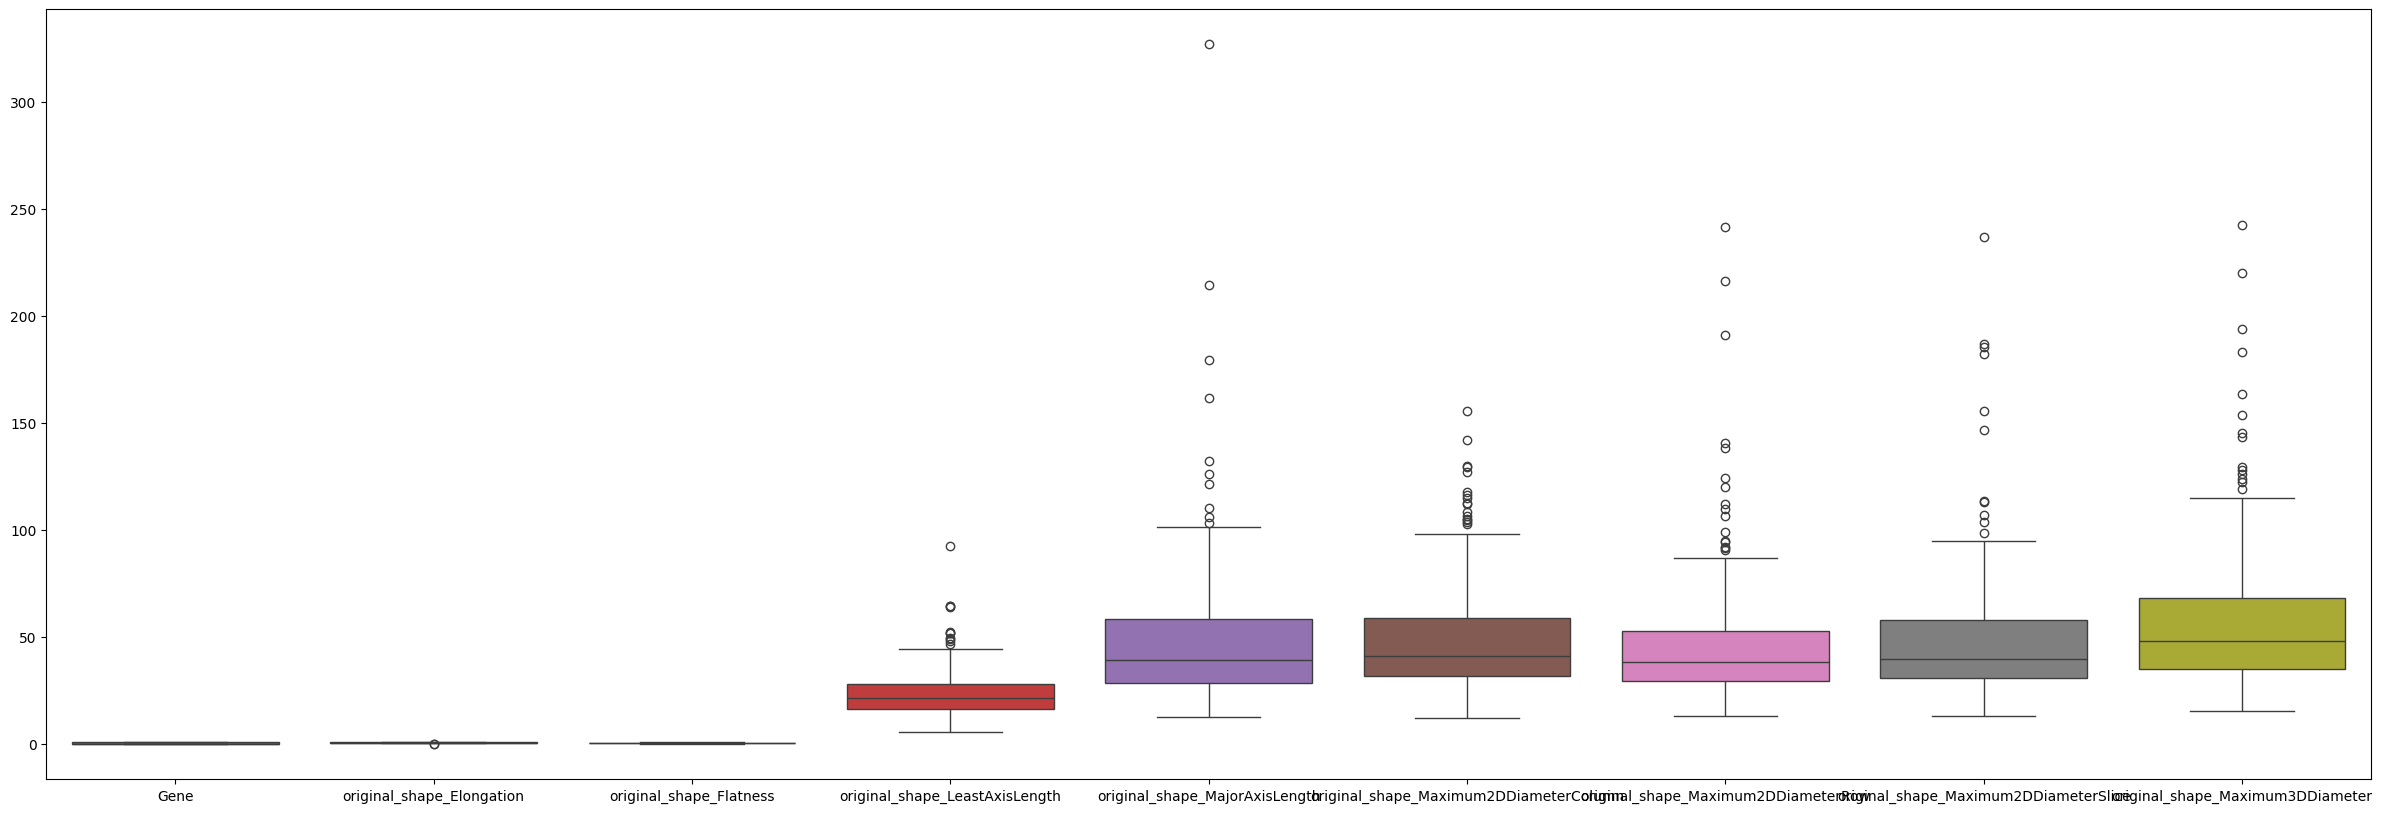

In [13]:
# Plot boxplots to visualise the data ranges of some ranges and check if there are outliers
fig, ax = plt.subplots(1, figsize = (30, 10))
sns.boxplot(data = X_train_eda.iloc[:, 10:19], ax = ax)

<Axes: >

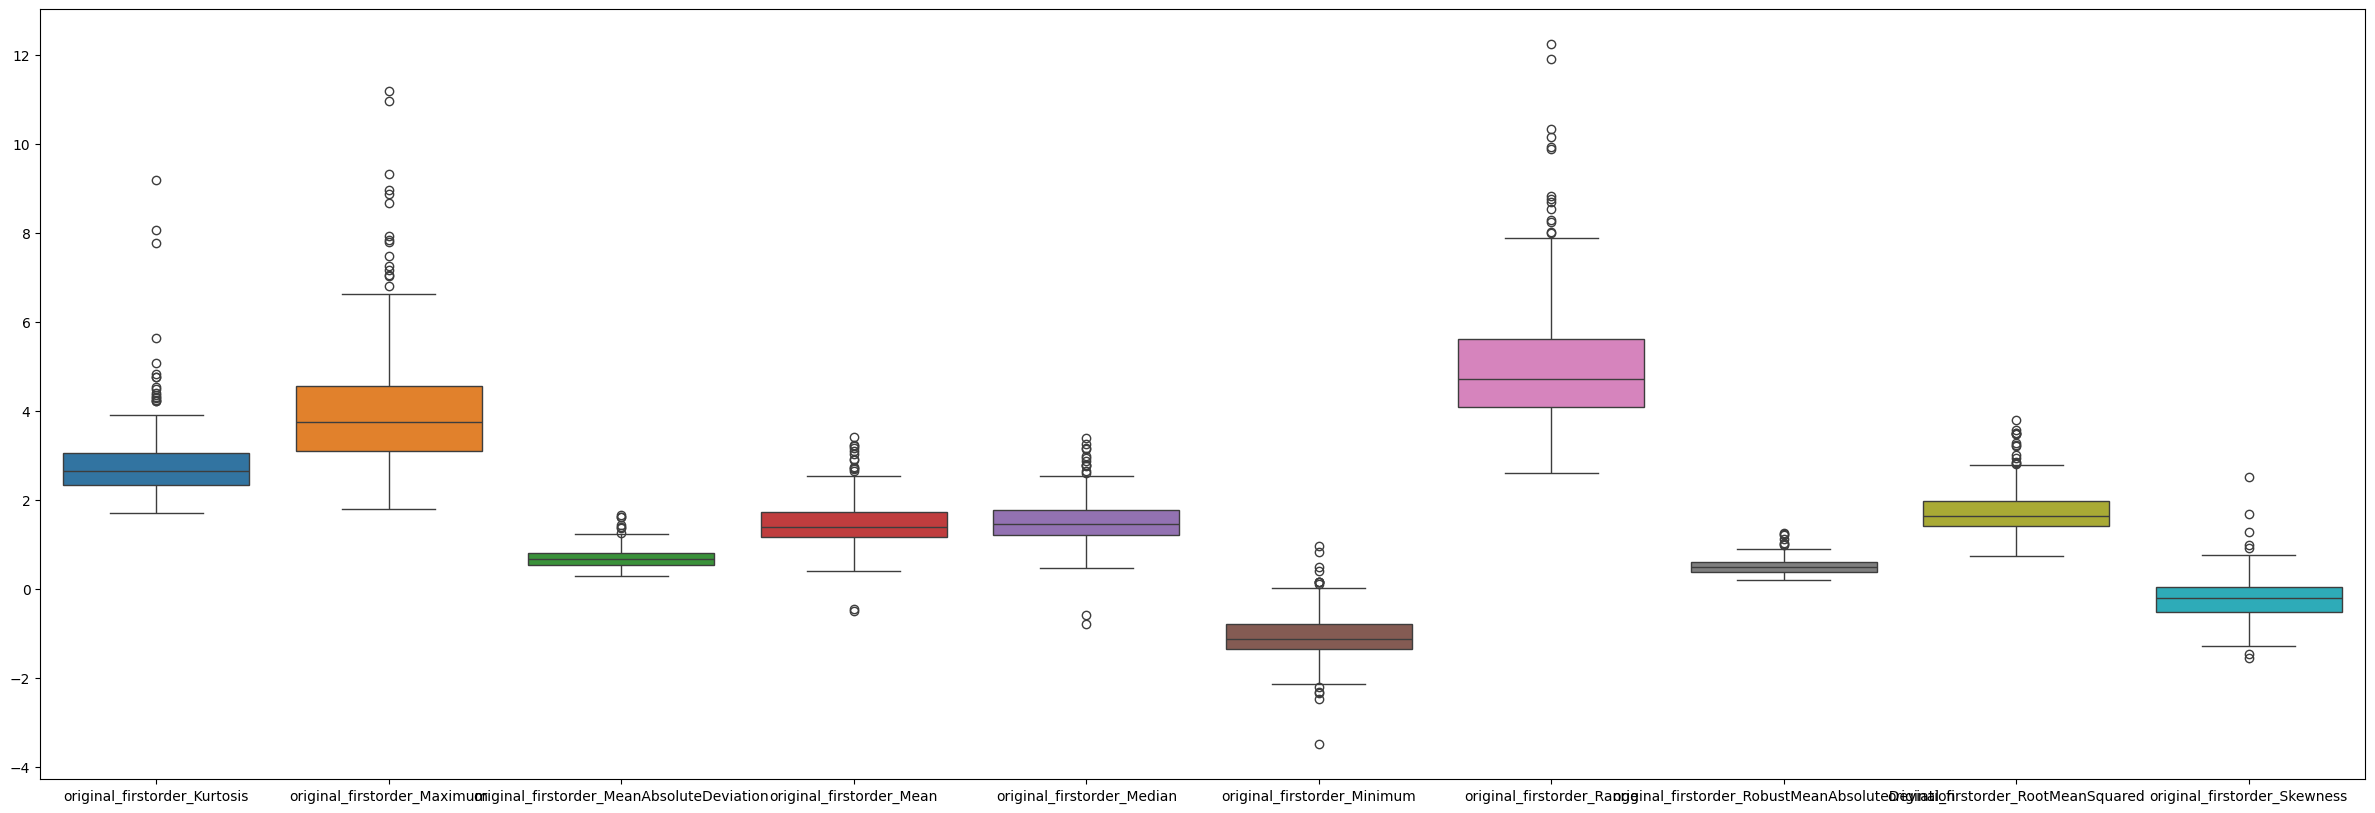

In [14]:
# Visualise the data ranges of some of the other features.
fig, ax = plt.subplots(1, figsize = (30, 10))
sns.boxplot(data = X_train_eda.iloc[:, 30:40], ax = ax)

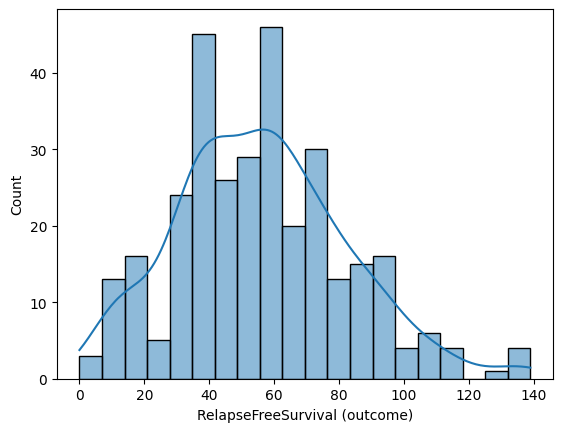

In [15]:
# Plot a histogram showing distribution of the RFS values (target)
sns.histplot(y_train, bins=20, kde=True)
plt.show()

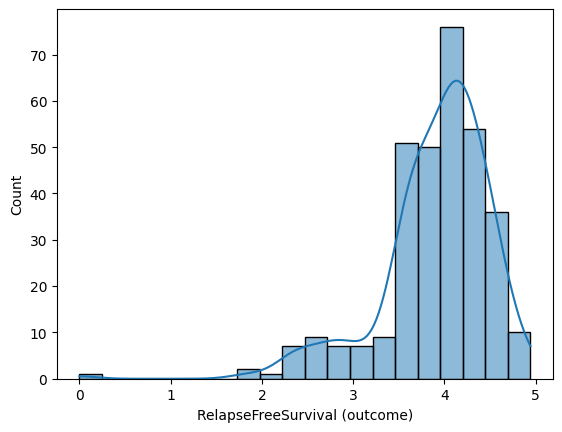

In [16]:
# Apply a log transformation to the RFS to handle right skewness
# This means that when evaluating and visualising predictions for models fitted to transformed RFS values during training, they must be transformed using the inverse (exponential)
y_train_final = y_train.copy()

y_train_log = np.log1p(y_train)
sns.histplot(y_train_log, bins = 20, kde = True)
plt.show()

### 2. Checking for Duplicate Rows

In [17]:
# Create DataFrame copies of the features before preprocessing is applied
X_train_transformed = X_train.copy()
X_train_final = X_train.copy()

In [18]:
# Check if there are any duplicate rows in the training data. If there are, keep the first occurence of that row and drop the other occurences
duplicate_rows = X_train_transformed[X_train_transformed.duplicated()]
print("Duplicate rows found:", duplicate_rows)

Duplicate rows found: Empty DataFrame
Columns: [Age, ER, PgR, HER2, TrippleNegative, ChemoGrade, Proliferation, HistologyType, LNStatus, TumourStage, Gene, original_shape_Elongation, original_shape_Flatness, original_shape_LeastAxisLength, original_shape_MajorAxisLength, original_shape_Maximum2DDiameterColumn, original_shape_Maximum2DDiameterRow, original_shape_Maximum2DDiameterSlice, original_shape_Maximum3DDiameter, original_shape_MeshVolume, original_shape_MinorAxisLength, original_shape_Sphericity, original_shape_SurfaceArea, original_shape_SurfaceVolumeRatio, original_shape_VoxelVolume, original_firstorder_10Percentile, original_firstorder_90Percentile, original_firstorder_Energy, original_firstorder_Entropy, original_firstorder_InterquartileRange, original_firstorder_Kurtosis, original_firstorder_Maximum, original_firstorder_MeanAbsoluteDeviation, original_firstorder_Mean, original_firstorder_Median, original_firstorder_Minimum, original_firstorder_Range, original_firstorder_Robu

### 3. Outlier Removal
Options: 
1. Z-Score
2. Interquartile Range

[Other Model-based methods:](https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/)

3. Isolation Forest
4. Local Outlier Factor

[Even More Model-based Methods](https://scikit-learn.org/stable/modules/outlier_detection.html#:~:text=OK-,2.7.1.%20Overview%20of%20outlier%20detection%20methods,-%23)

<Axes: >

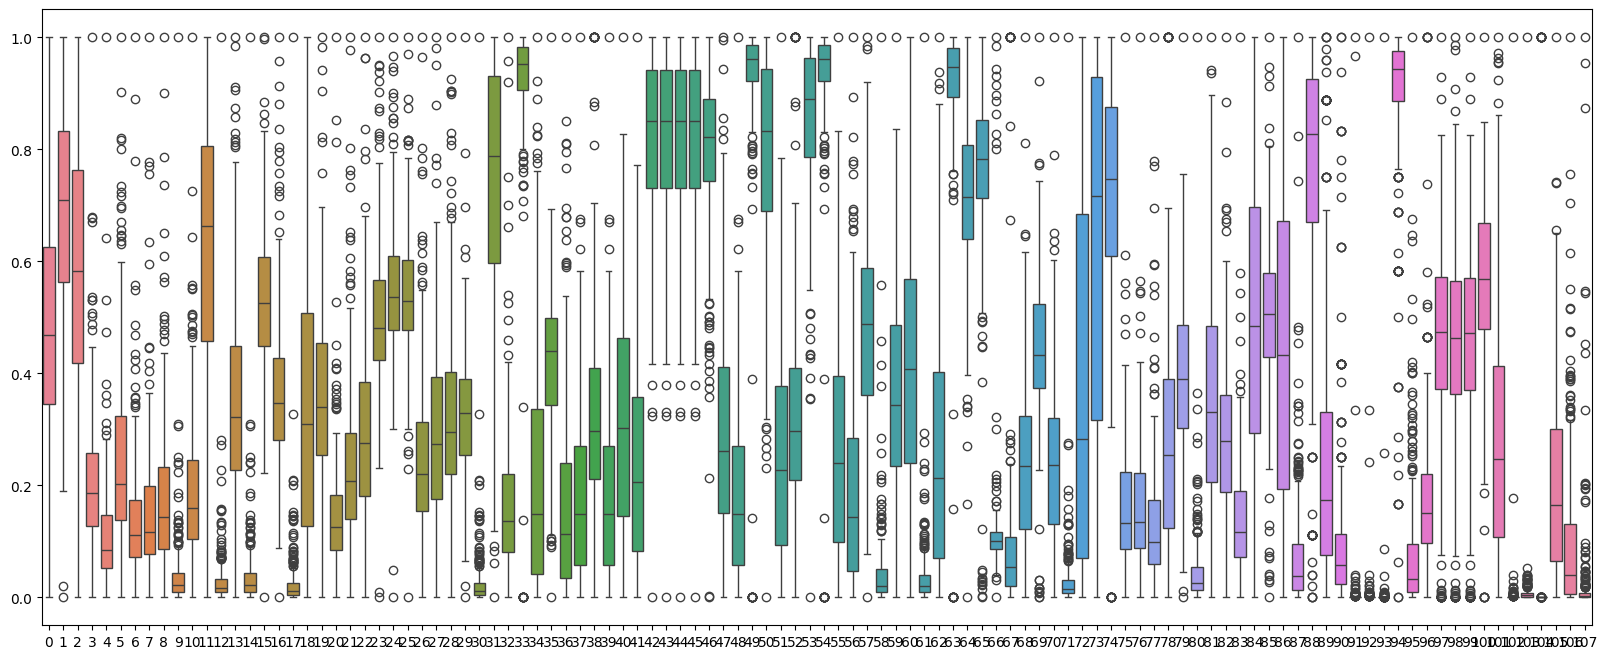

In [19]:
# Data visualisation
scaler = MinMaxScaler()

# Boxplot below shows normalised continuous features + outliers
fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data = scaler.fit_transform(X_train_eda[continuous_names]),ax=ax)

Note: Above boxplot, categorical features normalised to 0-1 range, shows prevalence of outliers. Handling using naive methods, such as Z-score or IQR, may be ineffective

##### Option 1 - Z-score

In [20]:
# Outlier Total
z_scores = np.abs(stats.zscore(X_train_transformed))
outliers_zscore = np.where(z_scores > 3)
outlier_indices = list(zip(outliers_zscore[0], outliers_zscore[1]))

print("Outlier total: "+str(len(outlier_indices)))

# # Outlier Locations

# for index in outlier_indices:
#    print(index)

Outlier total: 478


In [21]:
# Applying z-score

X_train_transformed[(np.abs(stats.zscore(X_train_transformed)) < 3).all(axis=1)] # < 3 checks for rows where all features are 3 standard deviations from the mean

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength


Note: Z-score is clearly ineffective. Implication from above cell is that outliers are prevalent in all samples, hence they are all removed

##### Option 2 - Interquartile Range

In [22]:
# Calculating Interquartile Range
q1 = X_train_transformed[continuous_names].quantile(0.25)
q3 = X_train_transformed[continuous_names].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr


In [23]:
# Outputting outlier total based on iqr
outliers_iqr = ((X_train_transformed[continuous_names] < lower_bound)) | (X_train_transformed[continuous_names] > upper_bound)
print(f"Outlier total: {outliers_iqr.sum().sum()}")

# Outputting columns containing outliers based on iqr
iqr_outliers_col = outliers_iqr.sum()
iqr_outliers_col = iqr_outliers_col[iqr_outliers_col > 0].sort_values(ascending=False)
print(f"\nOutlier locations:\n{iqr_outliers_col}")

Outlier total: 1560

Outlier locations:
original_ngtdm_Coarseness                          51
original_ngtdm_Strength                            48
original_glszm_LargeAreaLowGrayLevelEmphasis       45
original_glszm_LargeAreaEmphasis                   43
original_glszm_ZoneVariance                        42
                                                   ..
original_glcm_SumEntropy                            1
original_glcm_DifferenceVariance                    1
original_gldm_DependenceNonUniformityNormalized     1
original_glcm_DifferenceEntropy                     1
original_glcm_JointEntropy                          1
Length: 99, dtype: int64


In [24]:
# cap outliers using the lower/upper bound of the column
X_train[continuous_names] = np.where(X_train[continuous_names] < lower_bound, lower_bound, X_train[continuous_names])
X_train[continuous_names] = np.where(X_train[continuous_names] > upper_bound, upper_bound, X_train[continuous_names])

In [25]:
# Outputting resultant number of outliers per continuous column
outliers_iqr = ((X_train[continuous_names] < lower_bound) | (X_train[continuous_names] > upper_bound))
print(f"Outlier total: {outliers_iqr.sum().sum()}")

iqr_outliers_col = outliers_iqr.sum()
iqr_outliers_col = iqr_outliers_col[iqr_outliers_col > 0].sort_values(ascending=False)
print(f"\nOutlier locations:\n{iqr_outliers_col}")

Outlier total: 0

Outlier locations:
Series([], dtype: int64)


##### Option 3 - Isolation Forest
Method of anomaly detection that isolates outliers by building decision trees based on multiple splits. Supposedly better for high dimensions [[reference]](https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/#:~:text=IQR%20Method-,3.%20Isolation%20Forest,-Isolation%20Forest%20is)

Params include: contamination, random state and bootstrap [(among others that may be useful)](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html#:~:text=IsolationForest-,IsolationForest,-%23)
- contamination (float) is the percentage of outliers
- random state (int) is the pseudorandom seed
- bootstrap (bool) is an option to enable random sampling with replacement

In [26]:
#from sklearn.ensemble import IsolationForest

#iso = IsolationForest(contamination=0.05, random_state=42, bootstrap=True)
#y_pred_iso = iso.fit_predict(X_train)

#X_train["IsoForest_Outlier"] = y_pred_iso
#print(X_train["IsoForest_Outlier"].value_counts())

#plt.figure(figsize=(7, 5))
#sns.scatterplot(x="original_shape_Elongation", y="RelapseFreeSurvival (outcome)", data=X_train,
#                hue="IsoForest_Outlier", palette="coolwarm")
#plt.title("Isolation Forest Outlier Detection")
#plt.show()

<Axes: >

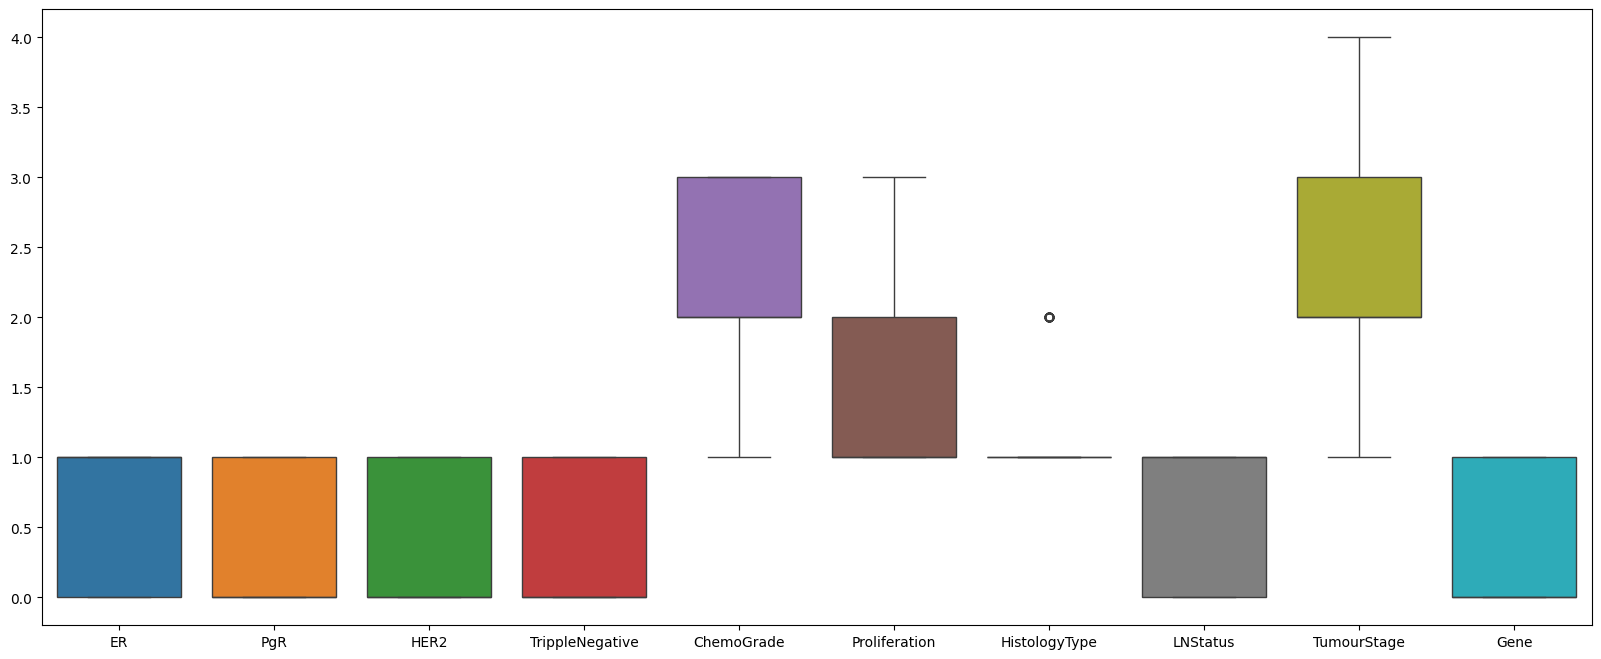

In [27]:
# Check value counts for categorical data, replace any questionable instances
fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=X_train[categorical_names],ax=ax)

Index(['RelapseFreeSurvival (outcome)', 'Age', 'original_shape_Elongation',
       'original_shape_Flatness', 'original_shape_LeastAxisLength',
       'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_Maximum2DDiameterSlice',
       'original_shape_Maximum3DDiameter',
       ...
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_glszm_SmallAreaLowGrayLevelEmphasis',
       'original_glszm_ZoneEntropy', 'original_glszm_ZonePercentage',
       'original_glszm_ZoneVariance', 'original_ngtdm_Busyness',
       'original_ngtdm_Coarseness', 'original_ngtdm_Complexity',
       'original_ngtdm_Contrast', 'original_ngtdm_Strength'],

### 4. Data Imputation
Performed after outlier handling as imputation should perform better with clean(er) data, especially for null values

Null values can be removed or imputed, or a combination of both consider only removing Gene null values, as other null totals are [minimal](#1-null-handling)  
- SimpleImputer for imputation by mean/mode/median
- IterativeImputer for model-based imputation

##### SimpleImputer

Options:
1. Removal of all null values
2. Partial Removal, Partial Imputation
3. Imputation of all null values

This has a 'missing_values' field, meaning we could set said field to 999 instead of the earlier conversion of 999 to NaN
- Prefer not to do so as '999' would negatively affect the distribution of data used in the models

In [28]:
# Viewing features with null values
print("Before Imputation: ")
missing_values = X_train_transformed.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values

Before Imputation: 


ChemoGrade        3
Proliferation     2
HistologyType     3
LNStatus          1
Gene             69
dtype: int64

In [29]:
# Impute missing values which is np.nan by default
imputer_mean = SimpleImputer(strategy = 'mean')
imputer_median = SimpleImputer(strategy = 'median')
imputer_mode = SimpleImputer(strategy = 'most_frequent')

##### Imputation of all null values
Imputing continuous|categorical features using either:
1. Mean|Mode
2. Median|Mode (Selected Transformation)

Mean|Mode Imputation

In [30]:
# X_train[continuous_names] = imputer_mean.fit_transform(X_train[continuous_names])
# X_train[categorical_names] = imputer_mode.fit_transform(X_train[categorical_names])

Median|Mode Imputation

(Median is less sensitive to outliers)

In [31]:
# For the continuous features, impute the missing values in each column with the median of that column
X_train_transformed[continuous_names] = imputer_median.fit_transform(X_train_transformed[continuous_names])
X_train_transformed[continuous_names]

,Age,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
199,36.783025,0.858831,0.824066,17.709457,21.490331,23.853721,25.059928,22.203603,25.553865,4844.000000,...,0.350799,0.350799,3.197160,0.003696,9.762004e+05,74.501409,0.004012,0.102368,0.011175,0.003570
43,69.000000,0.653366,0.545140,16.727687,30.685113,33.837849,29.154759,30.083218,34.597688,6674.166667,...,0.550507,0.550507,2.573220,0.005959,1.052641e+06,21.346044,0.012082,0.024663,0.000567,0.010516
307,60.000000,0.686668,0.487857,15.812660,32.412492,30.479501,33.015148,34.928498,39.166312,4190.833333,...,0.426840,0.426840,2.956748,0.007522,4.830177e+05,38.839662,0.007064,0.066551,0.004116,0.006365
166,38.143737,0.857085,0.590414,14.907903,25.249927,29.120440,27.892651,27.018512,29.883106,5444.416667,...,0.572002,0.572002,2.000000,0.002920,1.720824e+06,8.240840,0.030818,0.011843,0.000150,0.025057
64,45.653662,0.714724,0.356154,26.727082,75.043710,86.330759,68.468971,81.006173,87.017240,36630.791670,...,0.584634,0.583599,2.398050,0.002764,1.202316e+07,163.782516,0.001637,0.033111,0.001479,0.001571
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241,71.300000,0.695391,0.626946,39.560926,63.101032,67.416615,68.963759,64.845971,73.088987,43852.833330,...,0.411956,0.411956,3.573921,0.004671,8.211440e+06,448.101792,0.000618,0.073363,0.005057,0.000545
253,63.238877,0.496812,0.282268,24.027355,85.122390,80.653580,75.690158,57.974132,80.962954,25927.166670,...,0.409377,0.409376,3.305045,0.001730,6.755623e+06,476.373341,0.000653,0.117835,0.014701,0.000594
390,68.400000,0.432680,0.378268,17.152942,45.346050,47.634021,39.560081,26.476405,49.648766,7294.708333,...,0.476508,0.476508,2.755023,0.004610,1.456280e+06,34.211090,0.007661,0.035392,0.001197,0.006756
155,40.000000,0.543030,0.401235,19.681554,49.052429,41.761226,43.931765,38.078866,53.094256,10472.291670,...,0.404660,0.404660,3.386250,0.003987,2.235835e+06,104.017827,0.002675,0.070976,0.005043,0.002376


In [32]:
# For the categorical features, impute the missing values in each column with the mode of that column
X_train_transformed[categorical_names] = imputer_mode.fit_transform(X_train_transformed[categorical_names])
X_train_transformed[categorical_names]

,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,Gene
199,0.0,1.0,0.0,0.0,3.0,3.0,1.0,0.0,3.0,0.0
43,0.0,0.0,1.0,0.0,2.0,1.0,1.0,1.0,2.0,1.0
307,0.0,0.0,0.0,1.0,2.0,1.0,1.0,1.0,1.0,0.0
166,1.0,1.0,1.0,0.0,3.0,2.0,1.0,0.0,2.0,1.0
64,0.0,0.0,1.0,0.0,3.0,2.0,1.0,0.0,3.0,1.0
...,...,...,...,...,...,...,...,...,...,...
241,0.0,0.0,0.0,1.0,3.0,3.0,1.0,1.0,2.0,0.0
253,0.0,0.0,1.0,0.0,2.0,3.0,1.0,1.0,3.0,1.0
390,0.0,0.0,0.0,1.0,3.0,2.0,1.0,1.0,2.0,0.0
155,1.0,1.0,0.0,0.0,2.0,1.0,1.0,1.0,3.0,1.0


In [33]:
# Check if there any remaining null values after data imputation

missing_values = X_train_transformed.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values

Series([], dtype: int64)

### 5. a - Standardisation

#### Z-Score Normalisation (Standardisation)

<Axes: >

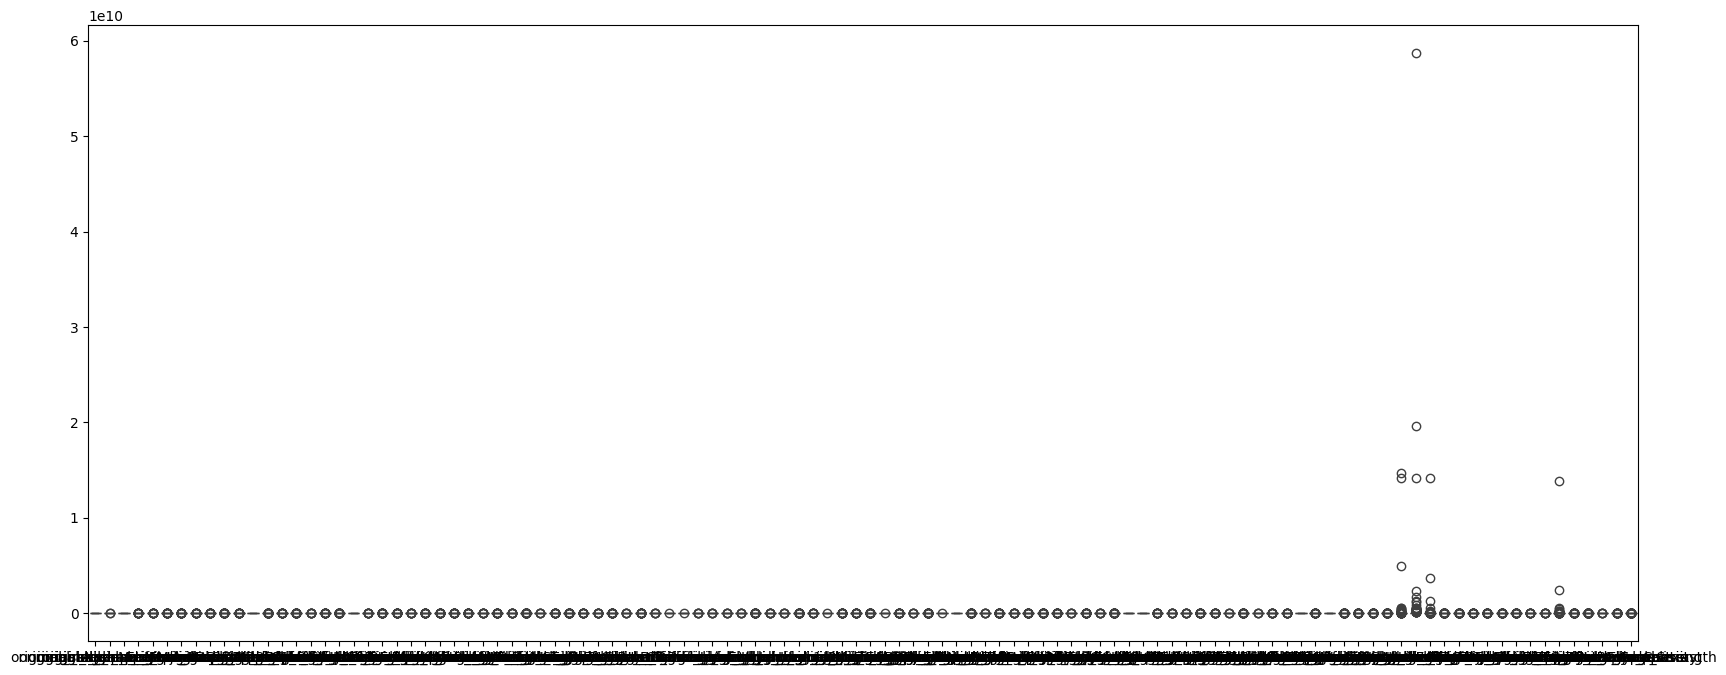

In [34]:
# View the data distribution before standardising the continuous features
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train_transformed[continuous_names], ax = ax)

<Axes: >

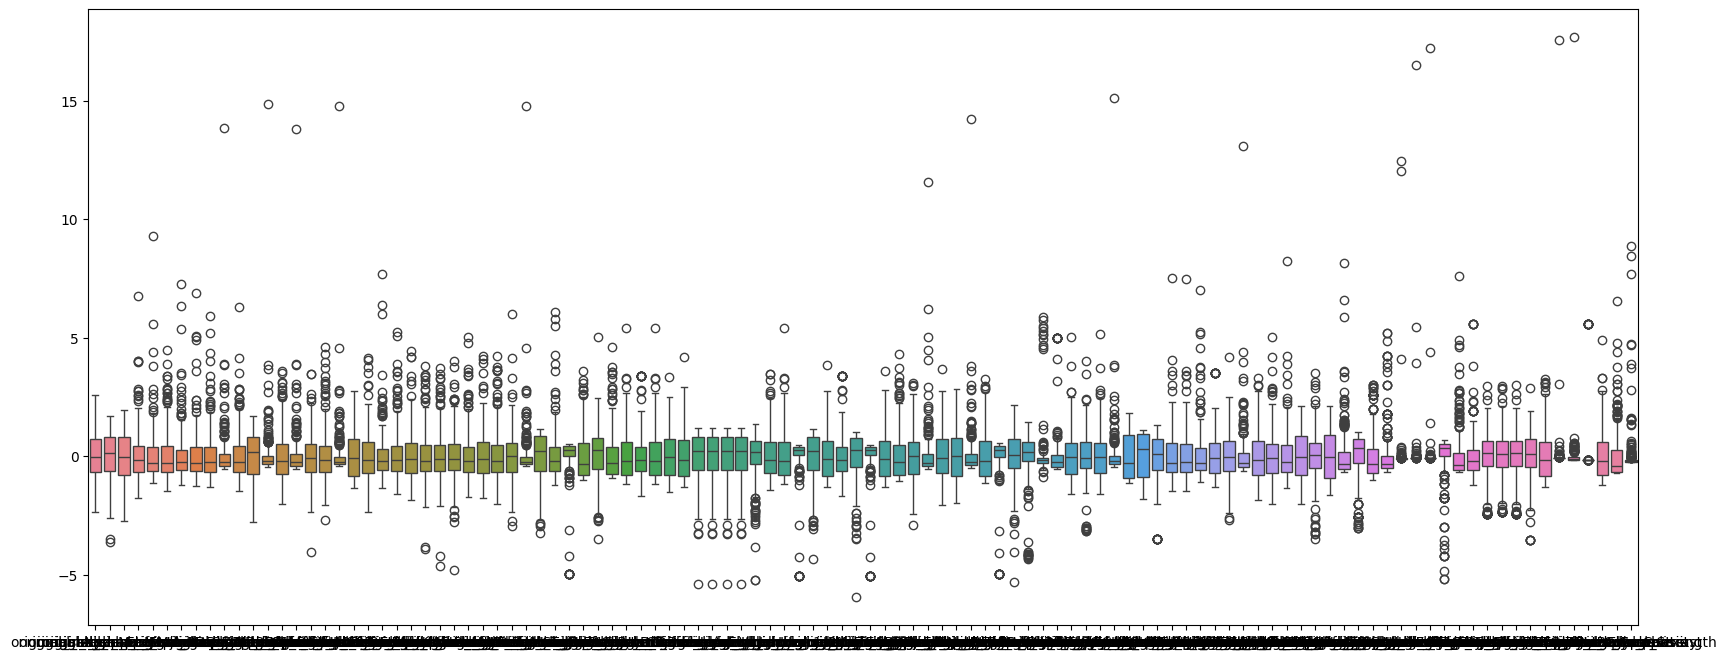

In [35]:
# Apply standardization on the continuous features
standard_scaler = StandardScaler()
X_train_transformed[continuous_names] = standard_scaler.fit_transform(X_train_transformed[continuous_names])

fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data = X_train_transformed[continuous_names], ax = ax)

In [36]:
# Check the new values of the continuous features after applying the transformation
X_train_transformed[continuous_names]

,Age,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
199,-1.380534,0.884772,1.661433,-0.555639,-0.856429,-1.008335,-0.756412,-0.925737,-0.973608,-0.436408,...,-0.246874,-0.223212,0.595470,0.178811,-0.083768,-0.101470,-0.179605,0.971160,0.620547,-0.220855
43,1.595167,-0.402264,-0.029533,-0.651512,-0.550824,-0.594071,-0.604993,-0.639815,-0.687406,-0.386573,...,0.967272,1.040166,-0.215316,1.096660,-0.083671,-0.147137,-0.179605,-0.691065,-0.644609,-0.165711
307,0.763888,-0.193659,-0.376807,-0.740866,-0.493411,-0.733416,-0.462243,-0.463998,-0.542826,-0.454194,...,0.215421,0.257829,0.283064,1.730433,-0.084394,-0.132107,-0.179605,0.204977,-0.221261,-0.198666
166,-1.254853,0.873835,0.244935,-0.829218,-0.731472,-0.789807,-0.651663,-0.751022,-0.836604,-0.420059,...,1.097950,1.176143,-0.960193,-0.136033,-0.082823,-0.158396,-0.179605,-0.965317,-0.694296,-0.050262
64,-0.561203,-0.017916,-1.175248,0.324955,0.923513,1.583976,0.848774,1.207990,0.971474,0.429147,...,1.174750,1.249510,-0.442942,-0.199296,-0.069746,-0.024766,-0.179605,-0.510359,-0.535763,-0.236727
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241,1.807605,-0.139015,0.466407,1.578213,0.526577,0.799186,0.867071,0.621596,0.530698,0.625804,...,0.124938,0.163677,1.085057,0.574280,-0.074584,0.219498,-0.179606,0.350694,-0.109129,-0.244871
253,1.063044,-1.382916,-1.623170,0.061320,1.258495,1.348417,1.115801,0.372243,0.779879,0.137687,...,0.109258,0.147353,0.735663,-0.618363,-0.076432,0.243787,-0.179606,1.302017,1.040997,-0.244484
390,1.539748,-1.784636,-1.041183,-0.609984,-0.063542,-0.021637,-0.220223,-0.770693,-0.211096,-0.369676,...,0.517387,0.572039,0.020930,0.549233,-0.083159,-0.136084,-0.179605,-0.461552,-0.569413,-0.195559
155,-1.083400,-1.093405,-0.901945,-0.363059,0.059646,-0.265313,-0.058566,-0.349683,-0.102060,-0.283150,...,0.080577,0.117516,0.841186,0.296814,-0.082169,-0.076111,-0.179605,0.299627,-0.110772,-0.230337


#### 5. b - One-Hot Encoding


This step parallels Normalisation, as an option for categorical features.

One hot encoding splits the categories in features into multiple features.

Parameters:
- drop_first = True: avoids multicollinearity, preventing dependence between one-hot encoded features

Notes:
- If making 'Age' categorical, avoid one-hot encoding it so we don't cause curse of dimensionality / make the model more computationally expensive.
- In retrospect, potential issue is that this is typically applied to non numerical data so it can be processed numerically.

In [37]:
# Apply One-Hot Encoding to the columns for the categorical features
#X_train_encoded = pd.get_dummies(X_train, columns = categorical_names, drop_first = True)
#X_train_encoded

#print(f"Before: {X_train.shape}\nAfter: {X_train_encoded.shape}")

In [38]:
#print(categorical_names)
#print(X_train_encoded.select_dtypes(bool).columns)

In [39]:
# Check that there are no longer any missing values for the features of each data point
#missing_values = X_train.isnull().sum()
#missing_values = missing_values[missing_values > 0]
#missing_values

# Feature Selection / Dimensionality reduction
### Note: specification says to keep the following features: 'ER', 'HER2' and 'Gene' 

Feature Selection
- Wrapper methods: forward feature selection, recursive feature elimination
- Embedded methods: LASSO, Decision Trees
- Filter based methods: t-tests, chi square, univariate ANOVA, correlation analysis, idk what else slides say


Dimensionality Reduction
- Includes: PCA, LDA, manifold learning
- Is manifold learning even applicable? 


First do Correlation analysis for visualisation: https://www.geeksforgeeks.org/machine-learning/data-preprocessing-machine-learning-python/#:~:text=Step%205%3A%20Correlation%20Analysis

- Also other methods in lab probably

### Feature Selection
Feature Selection aims to create a subset of the original features optimal for the model building process. This is split into 3 categories.
- Wrapper Methods
- Embedded Methods
- Filter-based Methods

##### Wrapper Methods
These likely take too long as they iterate through different feature permutations and evaluate them using an evaluation metric. Possibly apply after another method that has already reduced the number of features.

Options:
1. Forward Feature Selection
2. Recursive Feature Elimination



In [40]:
# Forward Feature Selection
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR


#sfs = SequentialFeatureSelector(SVR(kernel = 'linear'), n_features_to_select = 10, direction = 'forward', scoring = 'neg_mean_absolute_error')
#sfs.fit(X_train_transformed, y_train)
#sfs_mask = sfs.get_support()

#sfs_selected_features = X_train_transformed.columns[sfs_mask]

#print(sfs_selected_features)



In [41]:
# Recursive Feature Elimination
from sklearn.feature_selection import RFE
from sklearn.svm import SVR

#estimator = SVR(kernel = 'linear')

#selector_rfe = RFE(estimator, n_features_to_select = 38, step = 1)

#selector_rfe.fit(X_train_transformed, y_train)

#cols_rfe = X_train_transformed.columns[selector_rfe.get_support()]
#print(f"Top Recursive Feature Elimination Features:\n{cols_rfe.tolist()}")



##### Embedded Methods
Embed Feature Selection into the model process. Should probably use in the ML Method Development process.

Options:
1. LASSO (Regression)
2. Decision Trees / Random Forest

In [42]:
# LASSO Regression
#from sklearn.linear_model import Lasso
#from sklearn.feature_selection import SelectFromModel

# Alpha controls regularization strength (higher alpha -> fewer features selected)
#lasso = Lasso(alpha = 0.01)
#lasso.fit(X_train, y_train) # Using regression target here

#lasso_model = SelectFromModel(lasso, prefit = True)

#selected_features = pd.DataFrame({'Feature': X_train.columns, 'Selected': lasso_model.get_support()})
#print(selected_features[selected_features['Selected'] == True])

# Select features with non-zero weights
#lasso_coefs = pd.Series(np.abs(lasso.coef_), index = X_train.columns)
#print(f"Top 10 LASSO Features (Regression):\n{lasso_coefs.nlargest(10)}")

In [43]:
# Random Forest
#from sklearn.ensemble import RandomForestRegressor
#rf_model = RandomForestRegressor(n_estimators = 100, random_state = r_state)
#rf_model.fit(X_train, y_train)

# Extract feature importances
#importances = rf_model.feature_importances_

#feature_importance_df = pd.DataFrame({'Feature': X_train.columns, 'Importance': importances})
#print(feature_importance_df.sort_values(by='Importance', ascending=False))

# Extract feature importances
#feature_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
#print(f"Top RF Features:\n{feature_importances.nlargest(10)}")

##### Filter-based Methods
These methods are dependent on the datatypes of features (Xs) and outcomes (ys). Feature datatypes are both categorical and continuous, meaning different methods would have to be applied based on this. The classification outcome, 'pCR (outcome)', is categorical data; meanwhile the regression outcome, 'RelapseFreeSurvival (outcome)', is continuous data.

Options:

- t-test
- chi-square
- ANOVA
- Correlation Analysis

Note: t-test and chi-square test cannot be applied because there are no classes for the target variable

t-test requirements:
- Gaussian Distribution: data is close to gaussian distribution
- Binary Features: data contains binary features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outcome

Conclusion: Not Applicable, no classes for the target variable

ANOVA requirements:
- Categorical Features: dataset contains categorical features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outome

Conclusion: Applicable, features would need to be split

In [44]:
# ANOVA
#from sklearn.feature_selection import SelectKBest, f_regression

# Apply ANOVA to Continuous Features vs RFS
#anova_selector = SelectKBest(score_func = f_regression, k = 'all')
#anova_selector.fit(X_train, y_train)

#anova_scores = pd.DataFrame({
#    'Feature': X_train.columns,
#    'Score': anova_selector.scores_,
#    'P-Value': anova_selector.pvalues_
#}).sort_values(by = 'Score', ascending = False)

#print("Top 10 ANOVA Features (Continuous):\n", anova_scores.head(10))

Correlation Analysis requirements:
- Continuous Feature: dataset contains continuous features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outcome

Conclusion: Applicable, features would need to be split

In [45]:
# Correlation Analysis

# Calculate Pearson correlation of features with target variable RFS
corr_values = X_train.corrwith(y_train_log).abs().sort_values(ascending = False)
print("Top 10 Correlated Features (vs RelapseFreeSurvival):\n", corr_values.head(10))

Top 10 Correlated Features (vs RelapseFreeSurvival):
 original_shape_MajorAxisLength            0.230445
original_firstorder_Energy                0.230074
original_firstorder_TotalEnergy           0.230074
original_shape_Maximum3DDiameter          0.224474
original_shape_Maximum2DDiameterSlice     0.215231
original_shape_Maximum2DDiameterColumn    0.209844
TumourStage                               0.195878
original_firstorder_Maximum               0.188688
original_gldm_GrayLevelNonUniformity      0.185310
original_shape_VoxelVolume                0.184854
dtype: float64


### Dimensionality Reduction
Reduces the dimension of the data by generating new features from the old ones. This reduces interpretability, as new features are not the same as the old ones, hence we lose some understanding of the dataset

##### PCA (Principal Component Analysis)
This unsupervised learning method fits data to a new pair of axes so that it can be split using less features. This is done by calculating the mean (origin of new axes), covariance matrix (ellipse that contains the data), eigenvalues and eigenvectors of the covariance matrix (pair of new axes). 

scikit-learn pca has the following approach:
- n_components is the desired output feature total

In [46]:
from sklearn.decomposition import PCA

# Calculate the minimum dimension of PCA components needed to retain 90% of the variance of the training set
#pca = PCA(n_components = 0.9)
#Xs_pca = pca.fit_transform(X_train_transformed)
#pca_df = pd.DataFrame(Xs_pca, columns=['PCA_'+str(i+1) for i in range(Xs_pca.shape[1])])

#pca_df


In [47]:
#plt.figure(figsize = (6, 6))
#plt.scatter(Xs_pca[:, 0], Xs_pca[:, 1], alpha = 0.5)
#plt.xlabel('PCA 1')
#plt.ylabel('PCA 2')
#plt.title('PCA Plot')
#plt.show()

In [48]:
#fig = plt.figure(figsize = (10, 10))
#ax = fig.add_subplot(111, projection = '3d')

#ax.scatter(Xs_pca[:, 0], Xs_pca[:, 1], Xs_pca[:, 2], s = 50, alpha = 0.6)

#ax.set_xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0] * 100:.2f} % variance)')
#ax.set_ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1] * 100:.2f} % variance)')
#ax.set_zlabel(f'PCA 3 ({pca.explained_variance_ratio_[2] * 100:.2f} % variance)')

#plt.title('PCA Plot using 3 PCA Features')
#plt.show()

##### LDA (Linear Discriminant Analysis)
This supervised learning method projects data to a new pair of axes that helps split it into different classes. This is done by maximising the variance between data of different classes to separate them, and minimising the mean to keep datapoints within the same class together

Note: Cannot use LDA for RFS Regression because there are no class labels

In [49]:
#from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

#lda = LDA()
#lda.fit(X = X_train, y = y_train)

#lda.predict(X=[X_train.loc[1]])

# Machine Learning Method Development

### 1. Applying Preprocessing and Feature Selection
1. Preprocessing Pipeline
2. Apply Feature Selection

#### 1. Preprocessing Pipeline
- Create Pipeline that transforms test dataset using selected preprocessing methods
- Apply Pipeline

In [50]:
# Create a pipeline to handle preprocessing of categorical features
categorical_pipeline = Pipeline(
    steps = [("imputer", SimpleImputer(strategy = 'most_frequent'))]
)

# Create a pipeline to handle preprocessing of continuous features
continuous_pipeline = Pipeline(
    steps = [("imputer", SimpleImputer(strategy = 'median')),
             ("standard_scaler", StandardScaler())
    ]
)

# Create the full preprocessing pipeline using a ColumnTransformer. Apply the pipeline for categorical features and then the pipeline for continuous features
preprocessing_pipeline = ColumnTransformer(
    transformers = [("categorical", categorical_pipeline, categorical_names),
                    ("continuous", continuous_pipeline, continuous_names)
    ]
)


In [51]:
X_train_final.describe()

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
count,320.000000,320.000000,320.000000,320.000000,320.000000,317.000000,318.000000,317.000000,319.000000,320.000000,...,3.200000e+02,3.200000e+02,3.200000e+02,320.000000,3.200000e+02,320.000000,320.000000,320.000000,320.000000,320.000000
mean,51.729631,0.553125,0.412500,0.284375,0.334375,2.403785,1.584906,1.129338,0.542320,2.612500,...,3.914061e-01,3.860834e-01,2.738916e+00,0.003255,6.697370e+07,192.610101,31250.034953,0.056969,0.005972,0.031388
std,10.843640,0.497948,0.493055,0.451823,0.472510,0.497829,0.776646,0.336104,0.498989,0.885179,...,1.647420e-01,1.583222e-01,7.707546e-01,0.002470,7.890958e+08,1165.803206,174265.132389,0.046821,0.008398,0.126154
min,26.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,...,7.050000e-11,7.050000e-11,-3.200000e-16,0.000008,0.000000e+00,0.000000,0.000248,0.000000,0.000000,0.000000
25%,44.516769,0.000000,0.000000,0.000000,0.000000,2.000000,1.000000,1.000000,0.000000,2.000000,...,3.184399e-01,3.172598e-01,2.368600e+00,0.001229,1.160191e+06,21.757249,0.001798,0.018679,0.000336,0.001454
50%,51.119781,1.000000,0.000000,0.000000,0.000000,2.000000,1.000000,1.000000,1.000000,2.000000,...,4.066341e-01,4.045645e-01,2.816128e+00,0.002805,3.566217e+06,68.906053,0.004312,0.047134,0.002375,0.003262
75%,59.510609,1.000000,1.000000,1.000000,1.000000,3.000000,2.000000,1.000000,1.000000,3.000000,...,4.956924e-01,4.894076e-01,3.305720e+00,0.004672,9.989955e+06,160.966816,0.012093,0.085649,0.007995,0.009131
max,79.603012,1.000000,1.000000,1.000000,1.000000,3.000000,3.000000,2.000000,1.000000,4.000000,...,8.773779e-01,8.571429e-01,4.947427e+00,0.011301,1.390001e+10,20764.693790,1000000.000000,0.285100,0.060742,1.145601


In [52]:
# Cap outliers using the lower/upper bound of the column
# Calculating Interquartile Range
#q1 = X_train_final[continuous_names].quantile(0.25)
#q3 = X_train_final[continuous_names].quantile(0.75)
#iqr = q3 - q1

#lower_bound = q1 - 1.5 * iqr
#upper_bound = q3 + 1.5 * iqr

#X_train_final[continuous_names] = np.where(X_train_final[continuous_names] < lower_bound, lower_bound, X_train_final[continuous_names])
#X_train_final[continuous_names] = np.where(X_train_final[continuous_names] > upper_bound, upper_bound, X_train_final[continuous_names])

In [53]:
X_train_final.head()

missing_values = X_train_final.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values

ChemoGrade        3
Proliferation     2
HistologyType     3
LNStatus          1
Gene             69
dtype: int64

In [54]:
#X_train_final_transformed = preprocessing_pipeline.fit_transform(X_train_final)
#X_test_transformed = preprocessing_pipeline.transform(X_test)
median_imputer = SimpleImputer(strategy = 'median')
mode_imputer = SimpleImputer(strategy = 'most_frequent')
standard_scaler = StandardScaler()

X_train_final[categorical_names] = mode_imputer.fit_transform(X_train_final[categorical_names])
X_test[categorical_names] = mode_imputer.transform(X_test[categorical_names])

X_train_final[continuous_names] = median_imputer.fit_transform(X_train_final[continuous_names])
X_test[continuous_names] = median_imputer.transform(X_test[continuous_names])
X_train_final[continuous_names] = standard_scaler.fit_transform(X_train_final[continuous_names])
X_test[continuous_names] = standard_scaler.transform(X_test[continuous_names])


y_train_final_log = np.log1p(y_train_final)
y_test_log = np.log1p(y_test)

In [55]:
#features = preprocessing_pipeline.get_feature_names_out()
#X_train_final_transformed_df = pd.DataFrame(X_train_final_transformed, columns = features)
#X_test_transformed_df = pd.DataFrame(X_test_transformed, columns = features)

#### 2. Apply Feature Selection

In [56]:
from sklearn.feature_selection import RFECV
from sklearn.tree import DecisionTreeRegressor

#estimator = RandomForestRegressor(random_state = r_state)
#rfe_selector = RFECV(estimator, cv = 3, step = 2)
#rfe_selector.fit(X_train_final_transformed_df, y_train_final_log)

# Print the optimal number of features
#print("Optimal number of features:", rfe_selector.n_features_)

# Print the selected features
#cols_rfe = X_train_final_transformed_df.columns[rfe_selector.get_support()]
#print(f"Selected Features:\n{cols_rfe.tolist()}")


In [57]:
#rfe_sel = RFE(estimator = RandomForestRegressor(random_state = r_state), step = 2, n_features_to_select = 22)

### 2. Building Machine Learning Models

- Linear Regression
- Support Vector Regression
- Decision Tree Regressor
- Random Forest Regressor
- Multi-Layer Perceptron Network Regressor

Since the values for RFS were transformed using a logarithmic function, the predictions must be inversely transformed using an exponential function before using evaluation metrics and making visualisations

In [58]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error, r2_score

results = {}

#### Linear Regression

In [59]:
# Fit a linear regression model with default parameters to the preprocessed training data
lin_reg = LinearRegression()
#lin_reg.fit(X_train_final_selected, y_train)
#y_pred_lin = lin_reg.predict(X_train_final_selected)
lin_reg.fit(X_train_final, y_train_log)
y_pred_lin_log = lin_reg.predict(X_train_final)
y_pred_lin = np.expm1(y_pred_lin_log)

# Calculate the mean absolute error for the linear regression model  against the training data
print(f"Linear Regression MAE for Train Set: {mean_absolute_error(y_train, y_pred_lin)}")
print(f"Linear Regression RMSE for Train Set: {root_mean_squared_error(y_train, y_pred_lin)}")

Linear Regression MAE for Train Set: 16.396334149792168
Linear Regression RMSE for Train Set: 21.41169629118088


In [60]:
# Calculate the mean absolute error for the linear regression model against the unseen test data
y_pred_test_lin_log = lin_reg.predict(X_test)
y_pred_test_lin = np.expm1(y_pred_test_lin_log)
print(f"Linear Regression MAE for Test Set: {mean_absolute_error(y_test, y_pred_test_lin)}")
print(f"Linear Regression RMSE for Test Set: {root_mean_squared_error(y_test, y_pred_test_lin)}")

Linear Regression MAE for Test Set: 33.90448270503323
Linear Regression RMSE for Test Set: 49.94144294757679


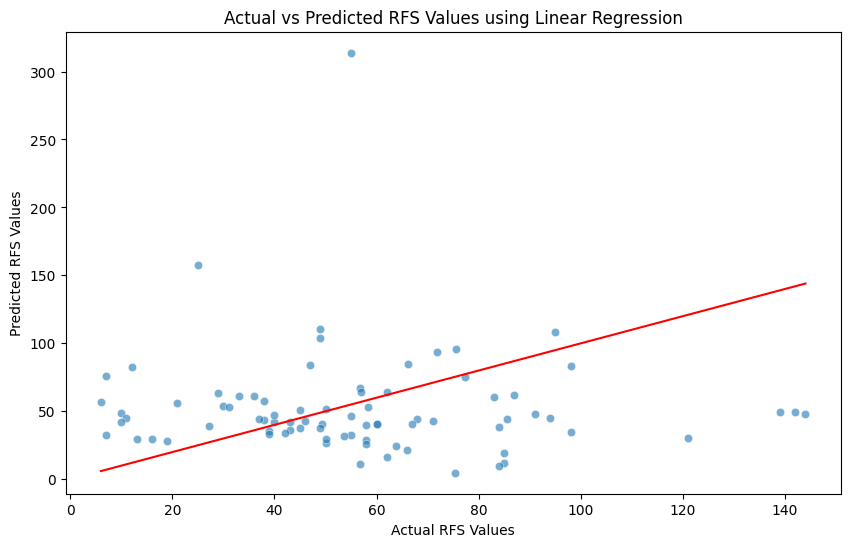

In [61]:
# Plot a scatter graph to visualise how well or how poor are the predictions for the linear regression model against the actual values
plt.figure(figsize=(10,6))
sns.scatterplot(x = y_test, y = y_pred_test_lin, alpha=0.6)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red')
plt.title('Actual vs Predicted RFS Values using Linear Regression')
plt.xlabel('Actual RFS Values')
plt.ylabel('Predicted RFS Values')
plt.show()

#### Support Vector Regression

In [62]:
# Fit a Support Vector Regression model on the preprocessed training data
#svr = SVR()
svr = SVR(kernel = 'rbf', epsilon = 0.5, C = 1)
svr.fit(X_train_final, y_train_log)
y_pred_svr_log = svr.predict(X_train_final)
y_pred_svr = np.expm1(y_pred_svr_log)

# Calculate the SVR model's mean absolute error against the training data
print(f"SVR MAE for Train Set: {mean_absolute_error(y_train, y_pred_svr)}")
print(f"SVR RMSE for Train Set {root_mean_squared_error(y_train, y_pred_svr)}")

SVR MAE for Train Set: 19.122178523338846
SVR RMSE for Train Set 23.578971971661044


In [63]:
y_pred_test_svr_log = svr.predict(X_test)
y_pred_test_svr = np.expm1(y_pred_test_svr_log)
# Calculate the SVR model's mean absolute error against the unseen test data
print(f"SVR MAE for Test Set: {mean_absolute_error(y_test, y_pred_test_svr)}")
print(f"SVR RMSE for Train Set {root_mean_squared_error(y_test, y_pred_test_svr)}")

SVR MAE for Test Set: 24.862402333191607
SVR RMSE for Train Set 32.47942888382043


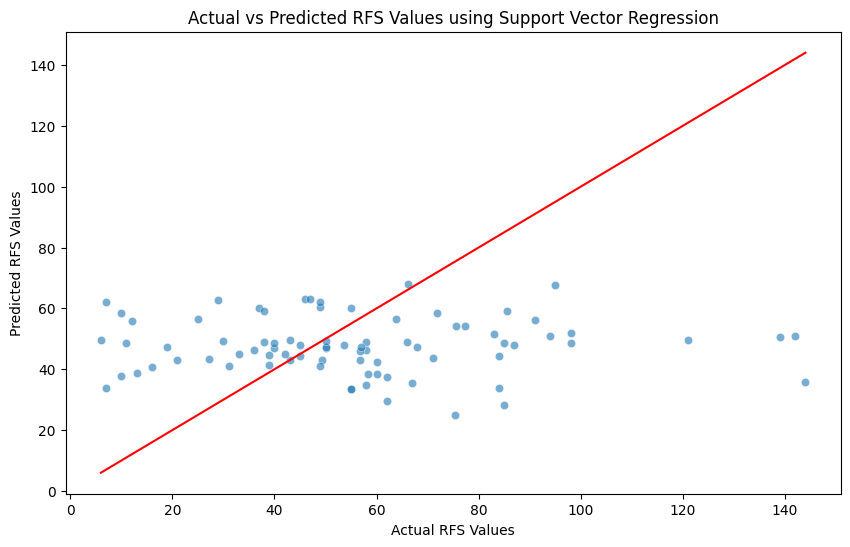

In [64]:
# Plot a scatter graph to visualise how well or how poor are the predictions for the SVR model against the actual values
plt.figure(figsize=(10,6))
sns.scatterplot(x = y_test, y = y_pred_test_svr, alpha=0.6)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red')
plt.title('Actual vs Predicted RFS Values using Support Vector Regression')
plt.xlabel('Actual RFS Values')
plt.ylabel('Predicted RFS Values')
plt.show()

#### Decision Tree Regressor

In [65]:
# Fit a Decision tree model on the preprocessed training data. Specify the random state so that the splitting at certain features is the same in each run
dt_reg = DecisionTreeRegressor(random_state = r_state)
dt_reg.fit(X_train_final, y_train_log)
y_pred_dt_log = dt_reg.predict(X_train_final)
y_pred_dt = np.expm1(y_pred_dt_log)

# Calculate the Decision Tree model's mean absolute error against the training data
print(f"Decision Tree MAE for Train Set: {mean_absolute_error(y_train, y_pred_dt)}")
print(f"Decision Tree RMSE Score for Test Set {root_mean_squared_error(y_train, y_pred_dt)}")

Decision Tree MAE for Train Set: 1.054989429150055e-14
Decision Tree RMSE Score for Test Set 1.5318905410340167e-14


In [66]:
# Calculate the Decision Tree model's mean absolute error against the unseen test data
y_pred_test_dt_log = dt_reg.predict(X_test)
y_pred_test_dt = np.expm1(y_pred_test_dt_log)
print(f"Decision Tree MAE for Test Set: {mean_absolute_error(y_test, y_pred_test_dt)}")
print(f"Decision Tree RMSE Score for Test Set {root_mean_squared_error(y_test, y_pred_test_dt)}")

Decision Tree MAE for Test Set: 29.56979166625
Decision Tree RMSE Score for Test Set 36.75047831296978


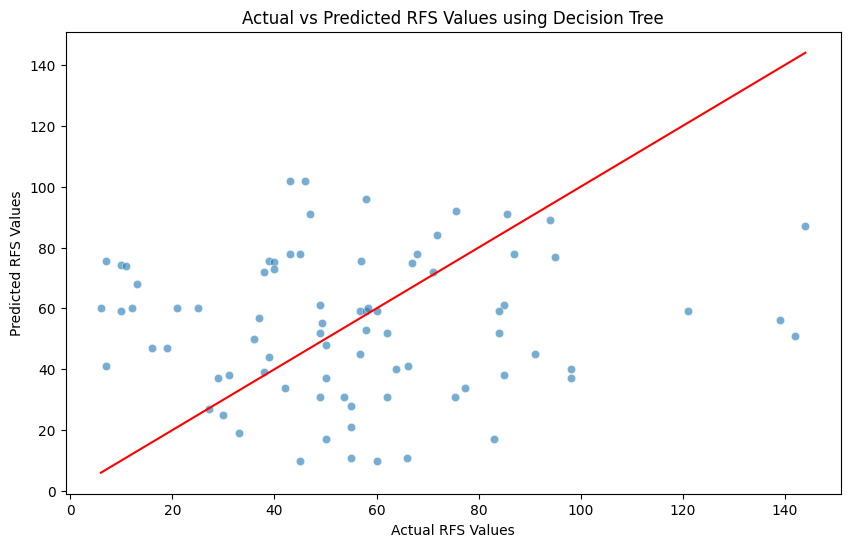

In [67]:
# Plot a scatter graph to visualise how well or how poor are the predictions for the Decision Tree model against the actual values
plt.figure(figsize=(10,6))
sns.scatterplot(x = y_test, y = y_pred_test_dt, alpha=0.6)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red')
plt.title('Actual vs Predicted RFS Values using Decision Tree')
plt.xlabel('Actual RFS Values')
plt.ylabel('Predicted RFS Values')
plt.show()

#### Random Forest Regressor

In [68]:
# Fit a Random Forest model on the preprocessed training data. Specify the random state so
rf_reg = RandomForestRegressor(random_state = r_state)
rf_reg.fit(X_train_final, y_train_log)
y_pred_rf_log = rf_reg.predict(X_train_final)
y_pred_rf = np.expm1(y_pred_rf_log)

# Calculate the Random Forest model's mean absolute error against the training data
print(f"Random Forest MAE on Train Set: {mean_absolute_error(y_train, y_pred_rf)}")
print(f"Random Forest RMSE on Train Set: {root_mean_squared_error(y_train, y_pred_rf)}")

Random Forest MAE on Train Set: 8.388114019770835
Random Forest RMSE on Train Set: 11.40945688094038


In [69]:
y_pred_test_rf_log = rf_reg.predict(X_test)
y_pred_test_rf = np.expm1(y_pred_test_rf_log)
# Calculate the Random Forest model's mean absolute error against the unseen test data
print(f"Random Forest MAE on Test Set: {mean_absolute_error(y_test, y_pred_test_rf)}")
print(f"Random Forest RMSE on Test Set: {root_mean_squared_error(y_test, y_pred_test_rf)}")

Random Forest MAE on Test Set: 25.1823905763022
Random Forest RMSE on Test Set: 32.19028888640386


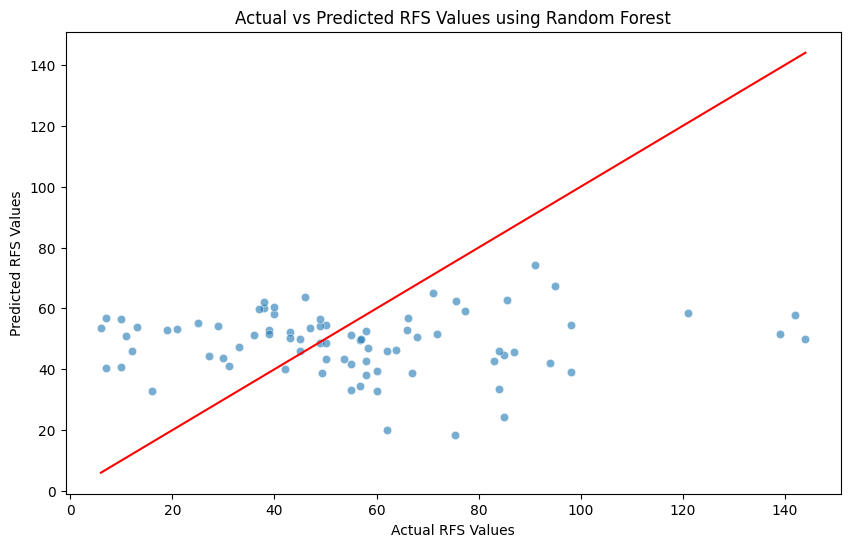

In [70]:
# Plot a scatter graph to visualise how well or how poor are the predictions for the Random Forest model against the actual values
plt.figure(figsize=(10,6))
sns.scatterplot(x = y_test, y = y_pred_test_rf, alpha=0.6)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red')
plt.title('Actual vs Predicted RFS Values using Random Forest')
plt.xlabel('Actual RFS Values')
plt.ylabel('Predicted RFS Values')
plt.show()

In [71]:
#X_train_final_transformed_df = pd.DataFrame(X_train_final_transformed, columns = X_train_final.columns)
X_train_final_selected = X_train_final.copy()
importances = rf_reg.feature_importances_
feature_names = X_train_final_selected.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by = 'Importance', ascending = False)
print(feature_importance_df[0:25]) # Gene --> 75th ranked, HER2 --> 99th ranked, ER --> 104th ranked

                                             Feature  Importance
110                       original_glszm_ZoneEntropy    0.071535
14                    original_shape_MajorAxisLength    0.053787
11                         original_shape_Elongation    0.042925
0                                                Age    0.028826
12                           original_shape_Flatness    0.025657
39                      original_firstorder_Skewness    0.024345
26                  original_firstorder_90Percentile    0.022341
106   original_glszm_SizeZoneNonUniformityNormalized    0.020506
36                         original_firstorder_Range    0.019113
31                       original_firstorder_Maximum    0.017481
30                      original_firstorder_Kurtosis    0.017171
89                         original_glrlm_RunEntropy    0.017030
91   original_glrlm_RunLengthNonUniformityNormalized    0.016871
35                       original_firstorder_Minimum    0.015595
42                      o

In [72]:
top_features = feature_importance_df['Feature'][:25].values
selected_features = top_features.tolist()
print("Selected Features Before:", selected_features)

Selected Features Before: ['original_glszm_ZoneEntropy', 'original_shape_MajorAxisLength', 'original_shape_Elongation', 'Age', 'original_shape_Flatness', 'original_firstorder_Skewness', 'original_firstorder_90Percentile', 'original_glszm_SizeZoneNonUniformityNormalized', 'original_firstorder_Range', 'original_firstorder_Maximum', 'original_firstorder_Kurtosis', 'original_glrlm_RunEntropy', 'original_glrlm_RunLengthNonUniformityNormalized', 'original_firstorder_Minimum', 'original_firstorder_Variance', 'original_shape_Sphericity', 'original_firstorder_RootMeanSquared', 'original_shape_Maximum3DDiameter', 'original_shape_LeastAxisLength', 'TumourStage', 'original_glrlm_RunLengthNonUniformity', 'original_glrlm_ShortRunHighGrayLevelEmphasis', 'original_shape_Maximum2DDiameterColumn', 'original_glcm_Imc1', 'original_glszm_ZonePercentage']


In [73]:
important_features = ['ER', 'HER2', 'Gene']

for f in important_features:
    if f not in selected_features:
        selected_features.append(f)

In [74]:
print("Selected Features After:", selected_features)


Selected Features After: ['original_glszm_ZoneEntropy', 'original_shape_MajorAxisLength', 'original_shape_Elongation', 'Age', 'original_shape_Flatness', 'original_firstorder_Skewness', 'original_firstorder_90Percentile', 'original_glszm_SizeZoneNonUniformityNormalized', 'original_firstorder_Range', 'original_firstorder_Maximum', 'original_firstorder_Kurtosis', 'original_glrlm_RunEntropy', 'original_glrlm_RunLengthNonUniformityNormalized', 'original_firstorder_Minimum', 'original_firstorder_Variance', 'original_shape_Sphericity', 'original_firstorder_RootMeanSquared', 'original_shape_Maximum3DDiameter', 'original_shape_LeastAxisLength', 'TumourStage', 'original_glrlm_RunLengthNonUniformity', 'original_glrlm_ShortRunHighGrayLevelEmphasis', 'original_shape_Maximum2DDiameterColumn', 'original_glcm_Imc1', 'original_glszm_ZonePercentage', 'ER', 'HER2', 'Gene']


In [75]:
X_train_final_selected = X_train_final_selected[selected_features]
X_test_selected = X_test[selected_features]


In [76]:
rf_reg_sel = RandomForestRegressor(random_state = r_state)
rf_reg_sel.fit(X_train_final_selected, y_train_log)
y_pred_rf_sel_log = rf_reg_sel.predict(X_train_final_selected)
y_pred_rf_sel = np.expm1(y_pred_rf_sel_log)

print(f"Mean MAE on Train Set: {mean_absolute_error(y_train, y_pred_rf_sel)}")
print(f"Mean RMSE on Train Set: {root_mean_squared_error(y_train, y_pred_rf_sel)}")

Mean MAE on Train Set: 8.224078684616211
Mean RMSE on Train Set: 11.42130186538744


In [77]:
y_pred_test_rf_sel_log = rf_reg_sel.predict(X_test_selected)
y_pred_test_rf_sel = np.expm1(y_pred_test_rf_sel_log)

print(f"Mean MAE on Test Set: {mean_absolute_error(y_test, y_pred_test_rf_sel)}")
print(f"Mean RMSE on Test Set: {root_mean_squared_error(y_test, y_pred_test_rf_sel)}")

Mean MAE on Test Set: 24.54857377356324
Mean RMSE on Test Set: 31.36819947093378


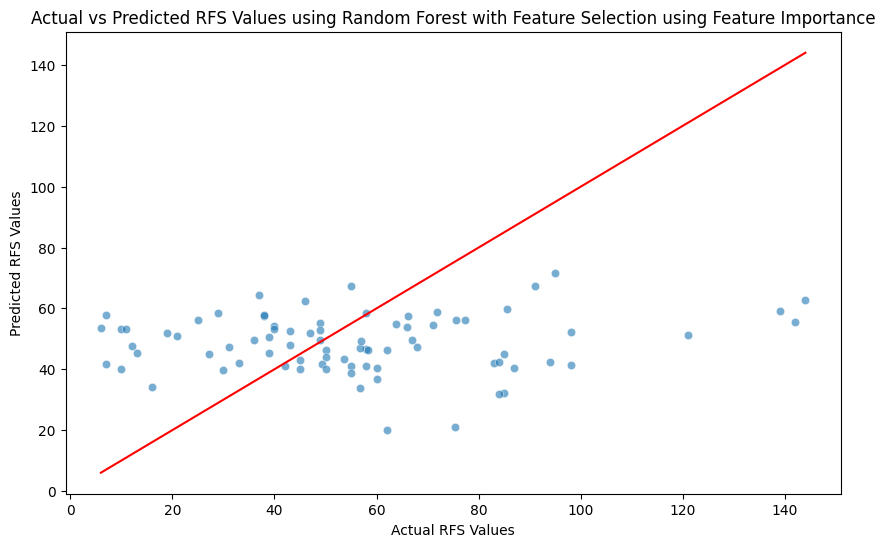

In [78]:
# Plot a scatter graph to visualise how well or how poor are the predictions for the Random Forest model against the actual values
plt.figure(figsize=(10,6))
sns.scatterplot(x = y_test, y = y_pred_test_rf_sel, alpha=0.6)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red')
plt.title('Actual vs Predicted RFS Values using Random Forest with Feature Selection using Feature Importance')
plt.xlabel('Actual RFS Values')
plt.ylabel('Predicted RFS Values')
plt.show()

In [79]:
joblib.dump(mode_imputer, './exports/rfs_mode_imputer.pkl')

joblib.dump(median_imputer, './exports/rfs_median_imputer.pkl')

joblib.dump(standard_scaler, './exports/rfs_standard_scaler.pkl')

joblib.dump(selected_features, './exports/rfs_selected_features.pkl')

joblib.dump(rf_reg_sel, './exports/rfs_random_forest.pkl')

['./exports/rfs_random_forest.pkl']

#### Multi-Layer Perceptron Network

In [80]:
# Fit a Multi-Layer Perceptron Network model on the preprocessed training data
mlp_reg = MLPRegressor(random_state = r_state)
mlp_reg.fit(X_train_final, y_train_log)
y_pred_mlp_log = mlp_reg.predict(X_train_final)
y_pred_mlp = np.expm1(y_pred_mlp_log)

# Calculate the MLP's mean absolute error against the training data
print(f"MLP MAE for Training Set: {mean_absolute_error(y_train, y_pred_mlp)}")
print(f"MLP RMSE for Training Set: {root_mean_squared_error(y_train, y_pred_mlp)}")

MLP MAE for Training Set: 13.244473888179822
MLP RMSE for Training Set: 18.167438194117793


C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [81]:
# Calculate the MLP's mean absolute error against the unseen test data
y_pred_test_mlp_log = mlp_reg.predict(X_test)
y_pred_test_mlp = np.expm1(y_pred_test_mlp_log)
print(f"MLP MAE for Test Set: {mean_absolute_error(y_test, y_pred_test_mlp)}")
print(f"MLP MAE for Test Set: {root_mean_squared_error(y_test, y_pred_test_mlp)}")

MLP MAE for Test Set: 31.51229443718274
MLP MAE for Test Set: 39.71180435391249


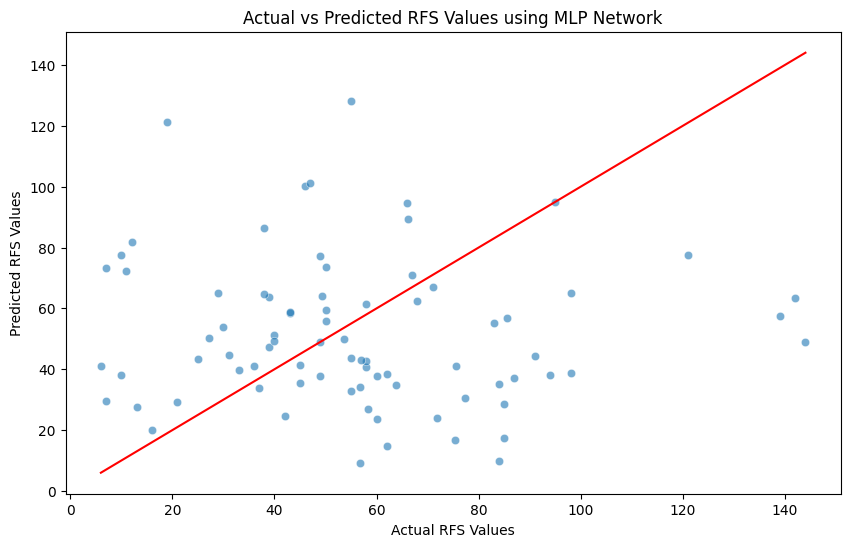

In [82]:
# Plot a scatter graph to visualise how well or how poor are the predictions for the MLP model against the actual values
plt.figure(figsize=(10,6))
sns.scatterplot(x = y_test, y = y_pred_test_mlp, alpha = 0.6)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red')
plt.title('Actual vs Predicted RFS Values using MLP Network')
plt.xlabel('Actual RFS Values')
plt.ylabel('Predicted RFS Values')
plt.show()

# Model Evaluation

- K-Fold Cross-Validation
- Mean Absolute Error

In [83]:
# Create a dictionary conatining the models that will be fitted to transformed RFS values
models_reg = {
    "Support Vector Regression": SVR(kernel = 'rbf', epsilon = 0.5, C = 1),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state = r_state),
    "Random Forest Regressor": RandomForestRegressor(random_state = r_state),
    "MLP Regressor": MLPRegressor(random_state = r_state)
}



In [84]:
# Set value for K to be used in K-Fold Cross Validation
k_fold = KFold(n_splits = 5, shuffle = True, random_state = r_state)
print(f"Using K = {k_fold} for K-Fold Cross-Validation")

results = {}

Using K = KFold(n_splits=5, random_state=12, shuffle=True) for K-Fold Cross-Validation


In [85]:
lin_reg_pipeline = Pipeline([
("preprocessing", preprocessing_pipeline),
        ("model", LinearRegression())
    ])

scores = cross_val_score(lin_reg_pipeline, x, y, cv = k_fold, scoring = "neg_mean_absolute_error")

print(f"MAE for Linear Regression at each iteration: {-scores}")
mean_score = -(np.mean(scores))
std_dev_score = np.std(scores)
print(f"Linear Regression: Mean MAE = {mean_score:,.2f} (+/- {std_dev_score:,.2f})\n")


MAE for Linear Regression at each iteration: [ 29.38249987  30.42816232 122.39726447  57.61620657  79.45210141]
Linear Regression: Mean MAE = 63.86 (+/- 34.68)



In [86]:
from sklearn.compose import TransformedTargetRegressor
# Iterate through the models in the dictionary and perform K-Fold Cross-Validation
# For each model, split the data into K-folds, apply the pipeline of preprocessing folds for training data and fitting the model onto that data, then evaluating the performance on the test fold
# using coefficient of determination (r^2)
for model_name, model in models_reg.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessing_pipeline),
        ("model", model)
    ])

    transformed_pipeline = TransformedTargetRegressor(regressor = pipeline, func = np.log1p, inverse_func = np.expm1)

    scores = cross_val_score(transformed_pipeline, x, y, cv = k_fold, scoring = "neg_mean_absolute_error")

    # For each model, output the r^2 at each iteration, mean r^2 and standard deviation of r^2
    print(f"MAE for {model_name} at each iteration: {scores}")
    mean_score = -np.mean(scores)
    std_dev_score = np.std(scores)
    results[model_name] = {"Mean MAE": mean_score, "Std Dev MAE": std_dev_score}
    print(f"{model_name}: Mean MAE = {mean_score:,.2f} (+/- {std_dev_score:,.2f})\n")


MAE for Support Vector Regression at each iteration: [-24.86240233 -20.57191276 -22.84249362 -23.60993064 -19.86648227]
Support Vector Regression: Mean MAE = 22.35 (+/- 1.87)

MAE for Decision Tree Regressor at each iteration: [-28.359375   -26.12708333 -29.36354167 -26.153125   -30.15833333]
Decision Tree Regressor: Mean MAE = 28.03 (+/- 1.65)

MAE for Random Forest Regressor at each iteration: [-25.02046022 -22.74461477 -22.78969988 -23.48817935 -19.56428149]
Random Forest Regressor: Mean MAE = 22.72 (+/- 1.78)



C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\danie\A

MAE for MLP Regressor at each iteration: [ -31.07985546  -24.85749647 -542.60258786  -32.43777236  -25.65279069]
MLP Regressor: Mean MAE = 131.33 (+/- 205.66)



C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [87]:
from sklearn.compose import TransformedTargetRegressor
# Iterate through the models in the dictionary and perform K-Fold Cross-Validation
# For each model, split the data into K-folds, apply the pipeline of preprocessing folds for training data and fitting the model onto that data, then evaluating the performance on the test fold
# using RMSE
for model_name, model in models_reg.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessing_pipeline),
        ("model", model)
    ])

    transformed_pipeline = TransformedTargetRegressor(regressor = pipeline, func = np.log1p, inverse_func = np.expm1)

    scores = cross_val_score(transformed_pipeline, x, y, cv = k_fold, scoring = "neg_root_mean_squared_error")

    # For each model, output the RMSE at each iteration, mean RMSE and standard deviation of RMSE
    print(f"RMSE for {model_name} at each iteration: {-scores}")
    mean_score = -(np.mean(scores))
    std_dev_score = np.std(scores)
    results[model_name] = {"Mean RMSE": mean_score, "Std Dev RMSE": std_dev_score}
    print(f"{model_name}: Mean RMSE = {mean_score:,.2f} (+/- {std_dev_score:,.2f})\n")

RMSE for Support Vector Regression at each iteration: [32.47942888 25.42234566 29.25715448 29.35061658 24.63401627]
Support Vector Regression: Mean RMSE = 28.23 (+/- 2.87)

RMSE for Decision Tree Regressor at each iteration: [35.41711397 35.91334575 36.18756956 34.76178482 38.47469406]
Decision Tree Regressor: Mean RMSE = 36.15 (+/- 1.26)

RMSE for Random Forest Regressor at each iteration: [32.08558804 28.6045941  29.04847616 29.39020698 25.34945998]
Random Forest Regressor: Mean RMSE = 28.90 (+/- 2.15)



C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\danie\A

RMSE for MLP Regressor at each iteration: [  37.93543628   32.49858207 4533.67604968   66.72714536   33.30788428]
MLP Regressor: Mean RMSE = 940.83 (+/- 1,796.47)



C:\Users\danie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
